# Data Cleaning & Visualization Project — Retail Sales Analysis

**Internship Project:** Data Cleaning & Visualization

This notebook takes a raw, messy retail sales dataset, inspects it, cleans it,
explores it, visualizes it, and extracts business insights — end to end.


## Objective

- Understand common real-world data quality problems (missing values, duplicates,
  inconsistent categories, outliers, mixed data types).
- Learn how to systematically clean a dataset with Pandas/NumPy.
- Practice Exploratory Data Analysis (EDA) and visualization with Matplotlib/Seaborn.
- Turn the analysis into clear, evidence-based insights (data storytelling).


## 3. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", None)


## 4. Load Dataset

We load the **raw** dataset exactly as it was collected — including its problems.
We will not modify this raw file; all cleaning happens on a copy in memory,
and the result is saved separately as the *cleaned* dataset.


In [2]:
raw_df = pd.read_csv("../data/raw_sales_dataset.csv")
raw_df.head()


,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Payment_Method,Customer_Age,Rating
0,ORD1174,2023-06-23,Meera Iyer,Kolkata,Tea Pack,Groceries,1,136.45,136.45,UPI,45.0,2.3
1,ORD1224,2023-07-15,Arjun Iyer,Delhi,Laptop,Electronics,1,35845.91,35845.91,Net Banking,18.0,2.5
2,ORD1085,2023-09-13,Ishaan Verma,Kolkata,Building Blocks,Toys,1,2144.37,2144.37,Cash,36.0,4.9
3,ORD1680,2023-03-01,Priya Sharma,Delhi,Shampoo,Beauty,1,627.51,627.51,UPI,38.0,4.5
4,ORD1536,2023-03-24,Aarav Singh,Bangalore,Rice 5kg,Groceries,1,393.65,393.65,UPI,34.0,4.4


## 5. Dataset Overview

In [3]:
print("Shape (rows, columns):", raw_df.shape)
print("\nColumn names:")
print(list(raw_df.columns))


Shape (rows, columns): (890, 12)

Column names:
['Order_ID', 'Order_Date', 'Customer_Name', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Sales', 'Payment_Method', 'Customer_Age', 'Rating']


In [4]:
raw_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 890 entries, 0 to 889
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        890 non-null    str    
 1   Order_Date      890 non-null    str    
 2   Customer_Name   890 non-null    str    
 3   City            863 non-null    str    
 4   Product         890 non-null    str    
 5   Category        890 non-null    str    
 6   Quantity        890 non-null    str    
 7   Unit_Price      871 non-null    str    
 8   Sales           890 non-null    float64
 9   Payment_Method  865 non-null    str    
 10  Customer_Age    838 non-null    float64
 11  Rating          845 non-null    float64
dtypes: float64(3), str(9)
memory usage: 142.0 KB


In [5]:
raw_df.tail()


,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Payment_Method,Customer_Age,Rating
885,ORD1716,2023-11-29,Priya Chatterjee,Ahmedabad,Sandals,Footwear,1,1302.94,1302.94,Cash,21.0,4.0
886,ORD1768,2023-03-27,Sneha Gupta,Delhi,Formal Shoes,Footwear,1,5564.32,5564.32,Debit Card,31.0,2.3
887,ORD1073,2023-05-10,Riya Gupta,Chennai,Running Shoes,Footwear,2,1839.93,3679.86,Net Banking,33.0,1.9
888,ORD1236,2023-11-16,Rahul Das,Mumbai,Comic Book,Books,1,271.85,271.85,UPI,43.0,4.8
889,ORD1038,2023-04-09,Diya Patel,Chennai,Dining Table,Furniture,1,17636.74,17636.74,Cash,NaN,4.1


## 6. Data Quality Assessment

Before touching anything, let's get a full picture of *what's wrong* with this data.


In [6]:
raw_df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,890,850,ORD1174,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,890,333,2023-07-07,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,890,334,Vivaan Patel,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,863,19,Ahmedabad,106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,890,37,Building Blocks,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,890,13,Toys,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,890,14,1,538,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unit_Price,871,832,136.45,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales,890.0,NaN,NaN,NaN,8249.771449,20339.561733,41.45,595.945,1675.465,5546.8125,211002.48
Payment_Method,865,8,Net Banking,175,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 7. Missing Value Analysis

Missing values (`NaN`) usually happen because of skipped form fields, failed sensors,
optional inputs, or merge issues. We check **how many** and **where**.


In [7]:
missing = raw_df.isna().sum()
missing_pct = (missing / len(raw_df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_%": missing_pct}).sort_values("missing_count", ascending=False)


,missing_count,missing_%
Customer_Age,52,5.84
Rating,45,5.06
City,27,3.03
Payment_Method,25,2.81
Unit_Price,19,2.13
Customer_Name,0,0.00
Order_ID,0,0.00
Order_Date,0,0.00
Quantity,0,0.00
Category,0,0.00


## 8. Duplicate Analysis

Duplicate rows can happen from double form submissions, repeated imports, or
logging errors. They inflate totals and distort averages if left in.


In [8]:
num_duplicates = raw_df.duplicated().sum()
print("Fully duplicated rows:", num_duplicates)
raw_df[raw_df.duplicated(keep=False)].sort_values("Order_ID").head(10)


Fully duplicated rows: 40


,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Payment_Method,Customer_Age,Rating
11,ORD1003,2023-06-19,Kavya Bose,Bangalore,Rice 5kg,Groceries,2,322.81,645.62,Cash,36.0,1.7
27,ORD1003,2023-06-19,Kavya Bose,Bangalore,Rice 5kg,Groceries,2,322.81,645.62,Cash,36.0,1.7
228,ORD1042,2023-05-06,Neha Das,Ahmedabad,Bookshelf,Furniture,1,3148.93,3148.93,Net Banking,25.0,4.0
775,ORD1042,2023-05-06,Neha Das,Ahmedabad,Bookshelf,Furniture,1,3148.93,3148.93,Net Banking,25.0,4.0
491,ORD1053,2023-03-22,Arjun Chatterjee,Chennai,Building Blocks,Toys,1,1025.71,1025.71,Credit Card,31.0,4.9
647,ORD1053,2023-03-22,Arjun Chatterjee,Chennai,Building Blocks,Toys,1,1025.71,1025.71,Credit Card,31.0,4.9
270,ORD1077,2023-07-21,Neha Patel,Kolkata,Bed Frame,Furniture,2,15103.34,30206.68,Debit Card,44.0,4.7
569,ORD1077,2023-07-21,Neha Patel,Kolkata,Bed Frame,Furniture,2,15103.34,30206.68,Debit Card,44.0,4.7
267,ORD1093,2023-06-21,Riya Joshi,Hyderabad,Remote Car,Toys,2,2565.85,5131.70,Debit Card,45.0,4.8
659,ORD1093,2023-06-21,Riya Joshi,Hyderabad,Remote Car,Toys,2,2565.85,5131.70,Debit Card,45.0,4.8


## 9. Data Type Analysis

`Quantity` and `Unit_Price` should be numeric, but a few rows contain text
noise (e.g. `"3 units"`, `"₹1200.5"`), which forces Pandas to store the whole
column as `object` (text) instead of a number.


In [9]:
print(raw_df.dtypes)
print()
print("Sample messy Quantity values:")
print(raw_df["Quantity"].astype(str).str.extract(r"([a-zA-Z]+)").dropna().head())
print()
print("Sample messy Unit_Price values:")
print(raw_df[raw_df["Unit_Price"].astype(str).str.contains("₹", na=False)]["Unit_Price"].head())


Order_ID              str
Order_Date            str
Customer_Name         str
City                  str
Product               str
Category              str
Quantity              str
Unit_Price            str
Sales             float64
Payment_Method        str
Customer_Age      float64
Rating            float64
dtype: object

Sample messy Quantity values:
         0
23   units
25   units
268  units
597  units
606  units

Sample messy Unit_Price values:
35     ₹7471.78
399     ₹341.25
499     ₹213.01
614    ₹2652.95
842      ₹64.48
Name: Unit_Price, dtype: str


## 10. Outlier Analysis

We use the **IQR (Interquartile Range) method**: values below `Q1 - 1.5*IQR` or
above `Q3 + 1.5*IQR` are flagged as statistical outliers.

Important: a statistical outlier is **not automatically wrong**. A ₹90,000
laptop is a genuine high-value sale, not an error — while a "customer age of 2"
is clearly a data-quality issue. We look at each flagged column with that lens
before deciding what to do with it.


In [10]:
numeric_cols_raw = raw_df.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns detected in the raw data:", numeric_cols_raw)

def iqr_outlier_count(series):
    s = pd.to_numeric(series, errors="coerce").dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < low) | (s > high)).sum(), low, high

for col in ["Sales", "Customer_Age", "Rating"]:
    count, low, high = iqr_outlier_count(raw_df[col])
    print(f"{col}: {count} potential outliers (bounds: {low:.2f} to {high:.2f})")


Numeric columns detected in the raw data: ['Sales', 'Customer_Age', 'Rating']
Sales: 132 potential outliers (bounds: -6830.36 to 12973.11)
Customer_Age: 4 potential outliers (bounds: 3.00 to 67.00)
Rating: 0 potential outliers (bounds: -1.00 to 7.00)


In [11]:
print("Suspicious Customer_Age values:", sorted(raw_df["Customer_Age"].dropna().unique())[:5],
      "...", sorted(raw_df["Customer_Age"].dropna().unique())[-5:])
print("Suspicious Rating values (should be 1-5):", sorted(raw_df["Rating"].dropna().unique()))
print("Negative Quantity rows:", raw_df["Quantity"].astype(str).str.contains("-").sum())


Suspicious Customer_Age values: [np.float64(2.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0)] ... [np.float64(63.0), np.float64(64.0), np.float64(69.0), np.float64(70.0), np.float64(99.0)]
Suspicious Rating values (should be 1-5): [np.float64(1.0), np.float64(1.1), np.float64(1.2), np.float64(1.3), np.float64(1.4), np.float64(1.5), np.float64(1.6), np.float64(1.7), np.float64(1.8), np.float64(1.9), np.float64(2.0), np.float64(2.1), np.float64(2.2), np.float64(2.3), np.float64(2.4), np.float64(2.5), np.float64(2.6), np.float64(2.7), np.float64(2.8), np.float64(2.9), np.float64(3.0), np.float64(3.1), np.float64(3.2), np.float64(3.3), np.float64(3.4), np.float64(3.5), np.float64(3.6), np.float64(3.7), np.float64(3.8), np.float64(3.9), np.float64(4.0), np.float64(4.1), np.float64(4.2), np.float64(4.3), np.float64(4.4), np.float64(4.5), np.float64(4.6), np.float64(4.7), np.float64(4.8), np.float64(4.9), np.float64(5.0), np.float64(6.0)]
Negative Quantity rows: 4


## 11. Data Cleaning

We now clean the data step by step. Each step is explained before the code.

**General rule we follow:** never blindly fill everything with 0, and never
remove every statistical outlier — the treatment is chosen per column based on
what makes sense for that column.


### 11.1 Standardize text columns (whitespace, inconsistent capitalization, aliases)

In [12]:
df = raw_df.copy()

# Trim whitespace and fix casing
df["Customer_Name"] = df["Customer_Name"].str.strip().str.title()
df["City"] = df["City"].str.strip().str.title().replace({"Bengaluru": "Bangalore"})
df["Category"] = df["Category"].str.strip().str.title().replace({"Cloths": "Clothing", "Foot Wear": "Footwear"})
df["Payment_Method"] = df["Payment_Method"].str.strip().str.title().replace({"Upi": "UPI"})

print("Unique City values after cleaning:", sorted(df["City"].dropna().unique()))
print("Unique Category values after cleaning:", sorted(df["Category"].dropna().unique()))


Unique City values after cleaning: ['Ahmedabad', 'Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'Mumbai', 'Pune']
Unique Category values after cleaning: ['Beauty', 'Books', 'Clothing', 'Electronics', 'Footwear', 'Furniture', 'Groceries', 'Toys']


### 11.2 Fix data types (Unit_Price and Quantity should be numeric)

In [13]:
df["Unit_Price"] = df["Unit_Price"].astype(str).str.replace("₹", "", regex=False).str.strip()
df["Unit_Price"] = pd.to_numeric(df["Unit_Price"], errors="coerce")

df["Quantity"] = df["Quantity"].astype(str).str.extract(r"(-?\d+)").astype(float)

print(df[["Unit_Price", "Quantity"]].dtypes)


Unit_Price    float64
Quantity      float64
dtype: object


### 11.3 Fix invalid values (negative quantity, out-of-range ratings)

In [14]:
# A negative Quantity is not a real business scenario here (not a returns dataset) -> sign error, take absolute value
df.loc[df["Quantity"] < 0, "Quantity"] = df.loc[df["Quantity"] < 0, "Quantity"].abs()

# Rating is only valid between 1 and 5 -> treat out-of-range values as missing
df.loc[(df["Rating"] < 1) | (df["Rating"] > 5), "Rating"] = np.nan

print("Remaining out-of-range ratings:", ((df['Rating'] < 1) | (df['Rating'] > 5)).sum())


Remaining out-of-range ratings: 0


### 11.4 Standardize dates

In [15]:
def parse_date(val):
    for fmt in ("%Y-%m-%d", "%d/%m/%Y"):
        try:
            return pd.to_datetime(val, format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.NaT

df["Order_Date"] = df["Order_Date"].apply(parse_date)
print("Unparseable dates left:", df["Order_Date"].isna().sum())


Unparseable dates left: 0


### 11.5 Recompute Sales consistently

In [16]:
recalculated_sales = df["Quantity"] * df["Unit_Price"]
mismatch = (df["Sales"] - recalculated_sales).abs() > 1
print("Rows where stored Sales did not equal Quantity x Unit_Price:", mismatch.sum())
df["Sales"] = recalculated_sales.round(2)


Rows where stored Sales did not equal Quantity x Unit_Price: 0


### 11.6 Handle missing values (column-appropriate strategy)

- `Customer_Age`, `Rating` → numeric → fill with **median** (robust to outliers, unlike mean)
- `City`, `Payment_Method` → categorical → fill with **mode** (most frequent value)
- `Unit_Price` → recompute from `Sales / Quantity` where possible, otherwise median
- `Order_Date` → cannot be guessed → rows with unparseable dates are dropped


In [17]:
before_missing = df.isna().sum()

df["Customer_Age"] = df["Customer_Age"].fillna(df["Customer_Age"].median())
df["Rating"] = df["Rating"].fillna(df["Rating"].median())
df["City"] = df["City"].fillna(df["City"].mode()[0])
df["Payment_Method"] = df["Payment_Method"].fillna(df["Payment_Method"].mode()[0])

mask_missing_price = df["Unit_Price"].isna() & df["Quantity"].notna() & (df["Quantity"] != 0)
df.loc[mask_missing_price, "Unit_Price"] = df.loc[mask_missing_price, "Sales"] / df.loc[mask_missing_price, "Quantity"]
df["Unit_Price"] = df["Unit_Price"].fillna(df["Unit_Price"].median())
df["Sales"] = (df["Quantity"] * df["Unit_Price"]).round(2)

df = df.dropna(subset=["Order_Date"])

after_missing = df.isna().sum()
pd.DataFrame({"before": before_missing, "after": after_missing})


,before,after
Order_ID,0,0
Order_Date,0,0
Customer_Name,0,0
City,27,0
Product,0,0
Category,0,0
Quantity,0,0
Unit_Price,19,0
Sales,19,0
Payment_Method,25,0


### 11.7 Remove duplicate rows

In [18]:
before_rows = len(df)
df = df.drop_duplicates()
print(f"Removed {before_rows - len(df)} duplicate rows ({before_rows} -> {len(df)})")


Removed 40 duplicate rows (890 -> 850)


### 11.8 Outlier treatment

We deliberately do **not** apply one global IQR rule to `Sales`/`Unit_Price`,
because categories like Electronics and Groceries naturally sit on very
different price scales — a global rule would wrongly flag most electronics
sales as "outliers". Instead:

- `Quantity`: statistically the IQR bound sits around 3.5, which would flag
  even normal bulk orders of 4-5 units. Since those are still realistic retail
  quantities, we only cap clearly implausible values (orders of 50-100 units,
  which were injected data-entry errors) using a **domain-based cap of 10**.
- `Customer_Age`: ages like 2, 3, 95, 99 are implausible for a retail customer
  → clipped to a realistic 16-85 range.
- `Unit_Price`: checked **per category** with a wide IQR multiplier (k=3), so
  only genuinely extreme, data-entry-error-like prices are capped — normal
  premium items are left untouched.


In [19]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

low_q, high_q = iqr_bounds(df["Quantity"])
print(f"Quantity IQR bounds (for reference only): {low_q:.2f} to {high_q:.2f}")
print("Values above domain cap of 10 (treated as errors):", (df['Quantity'] > 10).sum())
df["Quantity"] = df["Quantity"].clip(lower=1, upper=10)

low_a, high_a = iqr_bounds(df["Customer_Age"])
print(f"Customer_Age IQR bounds: {low_a:.2f} to {high_a:.2f}")
df["Customer_Age"] = df["Customer_Age"].clip(lower=16, upper=85)


Quantity IQR bounds (for reference only): -0.50 to 3.50
Values above domain cap of 10 (treated as errors): 3
Customer_Age IQR bounds: 7.00 to 63.00


In [20]:
def cap_per_category(frame, col, k=3):
    capped = frame.copy()
    total_flagged = 0
    for cat, group in frame.groupby("Category"):
        q1, q3 = group[col].quantile(0.25), group[col].quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - k * iqr, q3 + k * iqr
        mask = (group[col] < low) | (group[col] > high)
        total_flagged += mask.sum()
        capped.loc[group.index, col] = group[col].clip(lower=max(low, 0), upper=high)
    print(f"{col}: {total_flagged} extreme values capped (per-category IQR, k={k})")
    return capped

df = cap_per_category(df, "Unit_Price")
df["Sales"] = (df["Quantity"] * df["Unit_Price"]).round(2)


Unit_Price: 10 extreme values capped (per-category IQR, k=3)


### 11.9 Final dtype cleanup

In [21]:
df["Quantity"] = df["Quantity"].round().astype(int)
df["Customer_Age"] = df["Customer_Age"].round().astype(int)
df["Order_Date"] = pd.to_datetime(df["Order_Date"]).dt.strftime("%Y-%m-%d")
df = df.reset_index(drop=True)
df.head()


,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Payment_Method,Customer_Age,Rating
0,ORD1174,2023-06-23,Meera Iyer,Kolkata,Tea Pack,Groceries,1,136.45,136.45,UPI,45,2.3
1,ORD1224,2023-07-15,Arjun Iyer,Delhi,Laptop,Electronics,1,35845.91,35845.91,Net Banking,18,2.5
2,ORD1085,2023-09-13,Ishaan Verma,Kolkata,Building Blocks,Toys,1,2144.37,2144.37,Cash,36,4.9
3,ORD1680,2023-03-01,Priya Sharma,Delhi,Shampoo,Beauty,1,627.51,627.51,UPI,38,4.5
4,ORD1536,2023-03-24,Aarav Singh,Bangalore,Rice 5kg,Groceries,1,393.65,393.65,UPI,34,4.4


## 12. Cleaned Dataset Validation

A final check before saving: no missing values, no duplicates, sensible ranges.


In [22]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nRanges:")
print(df[["Quantity", "Unit_Price", "Sales", "Customer_Age", "Rating"]].describe())


Shape: (850, 12)

Missing values:
 Order_ID          0
Order_Date        0
Customer_Name     0
City              0
Product           0
Category          0
Quantity          0
Unit_Price        0
Sales             0
Payment_Method    0
Customer_Age      0
Rating            0
dtype: int64

Duplicate rows: 0

Ranges:
         Quantity    Unit_Price          Sales  Customer_Age      Rating
count  850.000000    850.000000     850.000000    850.000000  850.000000
mean     1.694118   4777.784624    7962.215529     35.048235    2.954588
std      1.183152   9690.794188   19392.510432     10.163274    1.132415
min      1.000000     40.780000      41.450000     16.000000    1.000000
25%      1.000000    450.925000     617.090000     28.000000    2.000000
50%      1.000000   1185.200000    1683.245000     35.000000    2.900000
75%      2.000000   3166.480000    5402.735000     42.000000    3.900000
max     10.000000  81478.820000  207310.500000     85.000000    5.000000


In [23]:
df.to_csv("../data/cleaned_sales_dataset.csv", index=False)
df.to_excel("../data/cleaned_sales_dataset.xlsx", index=False)
print("Cleaned dataset saved.")


Cleaned dataset saved.


## 13. Exploratory Data Analysis

We now ask specific, purposeful business questions of the cleaned data.


In [24]:
total_sales = df["Sales"].sum()
total_orders = len(df)
avg_order_value = df["Sales"].mean()
avg_rating = df["Rating"].mean()

print(f"Total Sales: ₹{total_sales:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Average Order Value: ₹{avg_order_value:,.2f}")
print(f"Average Customer Rating: {avg_rating:.2f} / 5")


Total Sales: ₹6,767,883.20


Total Orders: 850
Average Order Value: ₹7,962.22
Average Customer Rating: 2.95 / 5


In [25]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
category_sales


Category
Electronics    3176764.19
Furniture      2347156.95
Footwear        435166.28
Clothing        296762.01
Toys            256534.60
Beauty          134219.78
Books            87285.24
Groceries        33994.15
Name: Sales, dtype: float64

In [26]:
city_sales = df.groupby("City")["Sales"].sum().sort_values(ascending=False)
city_sales


City
Ahmedabad    1017605.23
Delhi         908450.15
Pune          802374.09
Bangalore     799829.20
Chennai       641473.74
Lucknow       606868.41
Hyderabad     585658.33
Kolkata       535295.09
Mumbai        452154.43
Jaipur        418174.53
Name: Sales, dtype: float64

In [27]:
monthly_sales = df.assign(Order_Date=pd.to_datetime(df["Order_Date"])) \
                   .set_index("Order_Date").resample("ME")["Sales"].sum()
monthly_sales


Order_Date
2023-01-31    851674.70
2023-02-28    495873.42
2023-03-31    813874.50
2023-04-30    615674.23
2023-05-31    296589.75
2023-06-30    607365.06
2023-07-31    620955.40
2023-08-31    581963.08
2023-09-30    518408.45
2023-10-31    444726.22
2023-11-30    375674.06
2023-12-31    545104.33
Freq: ME, Name: Sales, dtype: float64

In [28]:
top_products = df.groupby("Product")["Sales"].sum().sort_values(ascending=False).head(10)
top_products


Product
Smartphone      1532670.36
Dining Table     825155.16
Laptop           749313.41
Sofa             630263.19
Tablet           608217.50
Bed Frame        475759.42
Office Chair     250347.34
Smartwatch       183576.54
Formal Shoes     175839.30
Bookshelf        165631.84
Name: Sales, dtype: float64

In [29]:
payment_counts = df["Payment_Method"].value_counts()
payment_counts


Payment_Method
Cash           199
Net Banking    171
UPI            163
Debit Card     159
Credit Card    158
Name: count, dtype: int64

In [30]:
category_ratings = df.groupby("Category")["Rating"].mean().sort_values(ascending=False)
category_ratings


Category
Furniture      3.068269
Clothing       3.033663
Books          3.001905
Beauty         3.000000
Electronics    2.977451
Groceries      2.929412
Toys           2.850000
Footwear       2.798039
Name: Rating, dtype: float64

In [31]:
print("Correlation between Quantity and Sales:", round(df["Quantity"].corr(df["Sales"]), 3))
numeric_cols = ["Quantity", "Unit_Price", "Sales", "Customer_Age", "Rating"]
df[numeric_cols].corr()


Correlation between Quantity and Sales: 0.251


,Quantity,Unit_Price,Sales,Customer_Age,Rating
Quantity,1.000000,-0.011519,0.251045,-0.045691,0.010104
Unit_Price,-0.011519,1.000000,0.796812,-0.018956,0.019428
Sales,0.251045,0.796812,1.000000,-0.008973,0.033296
Customer_Age,-0.045691,-0.018956,-0.008973,1.000000,0.000037
Rating,0.010104,0.019428,0.033296,0.000037,1.000000


## 14. Visualizations

Each chart below answers one of the questions above, with a title, axis
labels, and readable values.


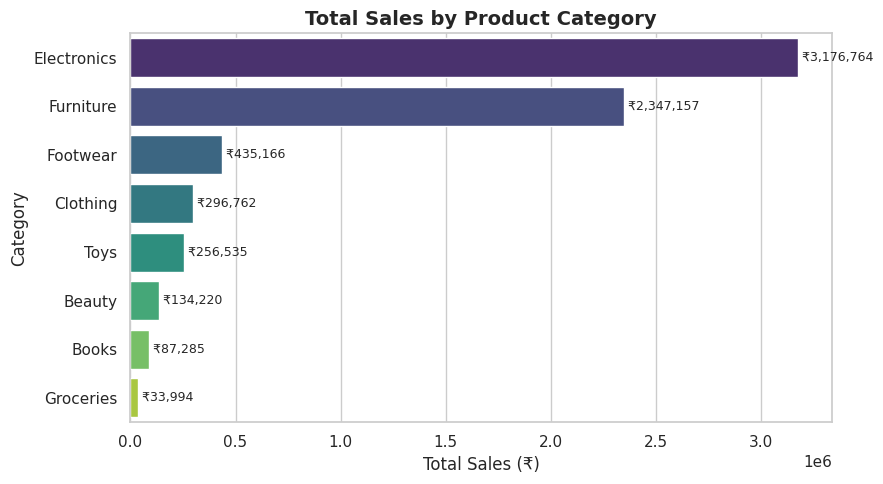

In [32]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(x=category_sales.values, y=category_sales.index,
                  hue=category_sales.index, palette="viridis", legend=False)
plt.title("Total Sales by Product Category", fontsize=14, fontweight="bold")
plt.xlabel("Total Sales (₹)")
plt.ylabel("Category")
for i, v in enumerate(category_sales.values):
    plt.text(v, i, f" ₹{v:,.0f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("../visualizations/sales_by_category.png")
plt.show()


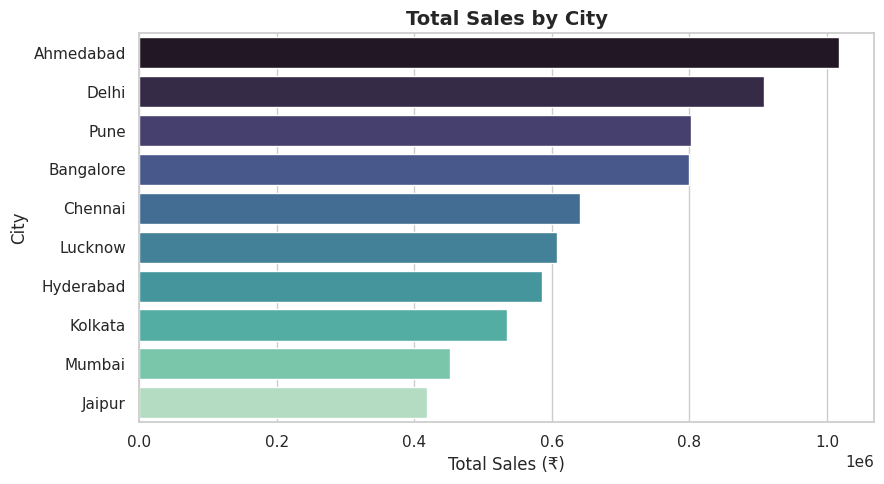

In [33]:
plt.figure(figsize=(9, 5))
sns.barplot(x=city_sales.values, y=city_sales.index, hue=city_sales.index,
            palette="mako", legend=False)
plt.title("Total Sales by City", fontsize=14, fontweight="bold")
plt.xlabel("Total Sales (₹)")
plt.ylabel("City")
plt.tight_layout()
plt.savefig("../visualizations/sales_by_city.png")
plt.show()


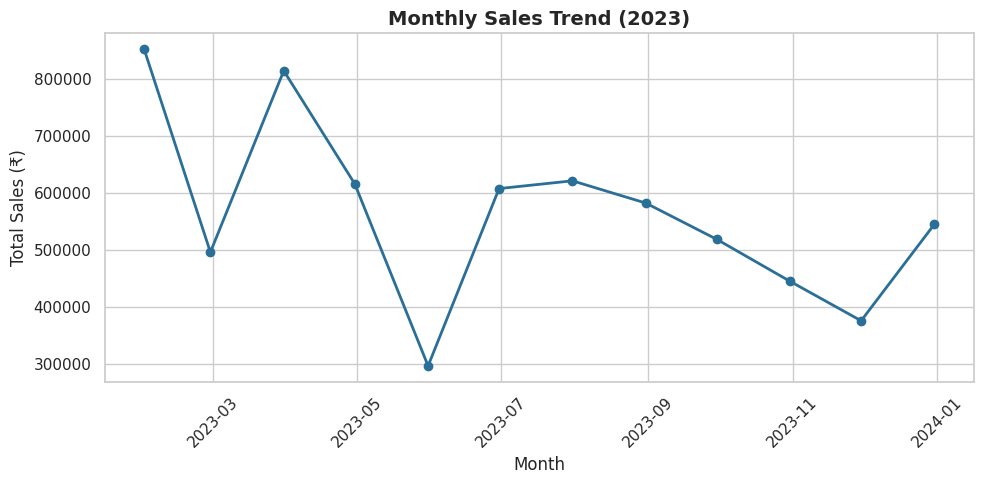

In [34]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o", color="#2a6f97", linewidth=2)
plt.title("Monthly Sales Trend (2023)", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../visualizations/monthly_sales_trend.png")
plt.show()


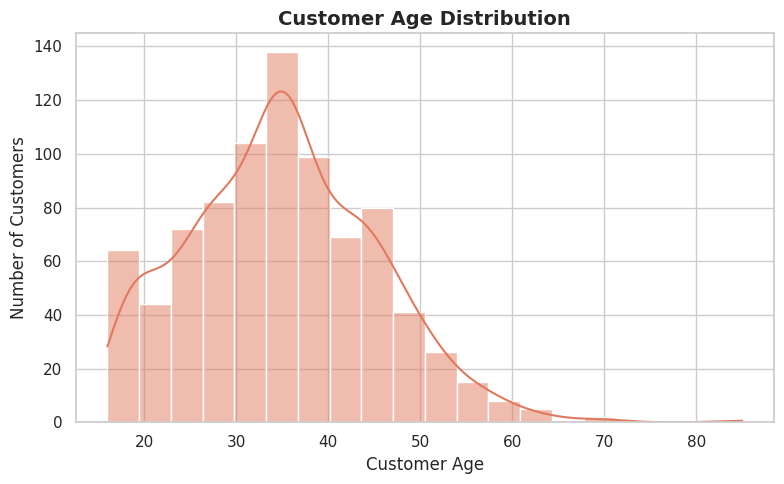

In [35]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Customer_Age"], bins=20, kde=True, color="#e07a5f")
plt.title("Customer Age Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("../visualizations/customer_age_distribution.png")
plt.show()


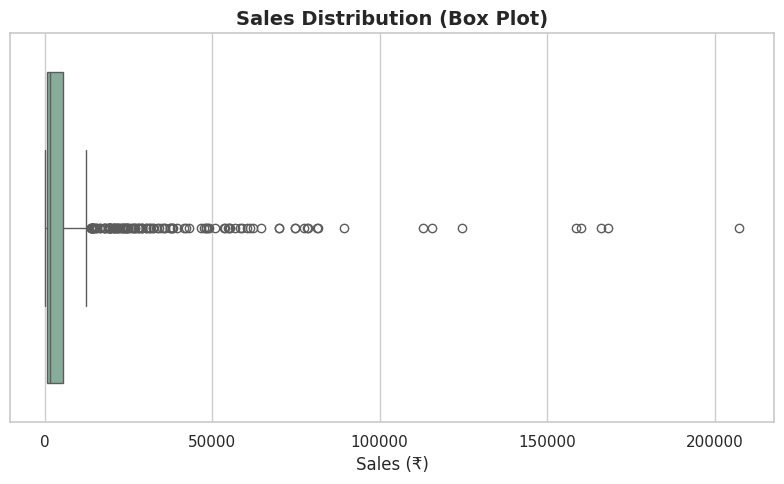

In [36]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Sales"], color="#81b29a")
plt.title("Sales Distribution (Box Plot)", fontsize=14, fontweight="bold")
plt.xlabel("Sales (₹)")
plt.tight_layout()
plt.savefig("../visualizations/sales_distribution.png")
plt.show()


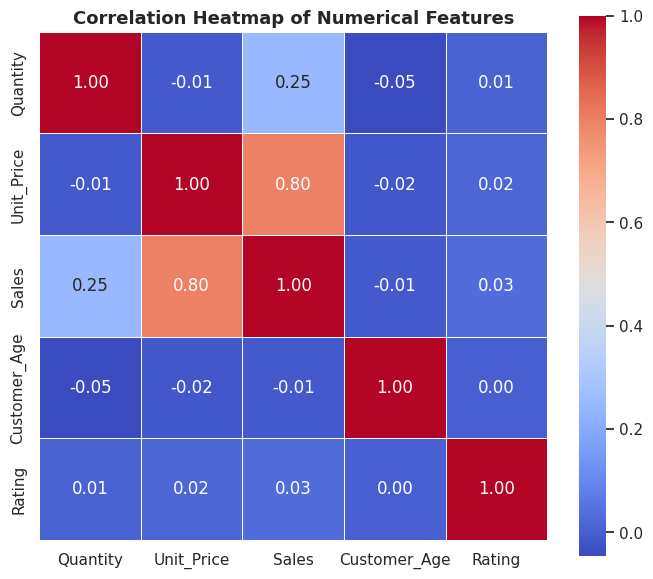

In [37]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../visualizations/correlation_heatmap.png")
plt.show()


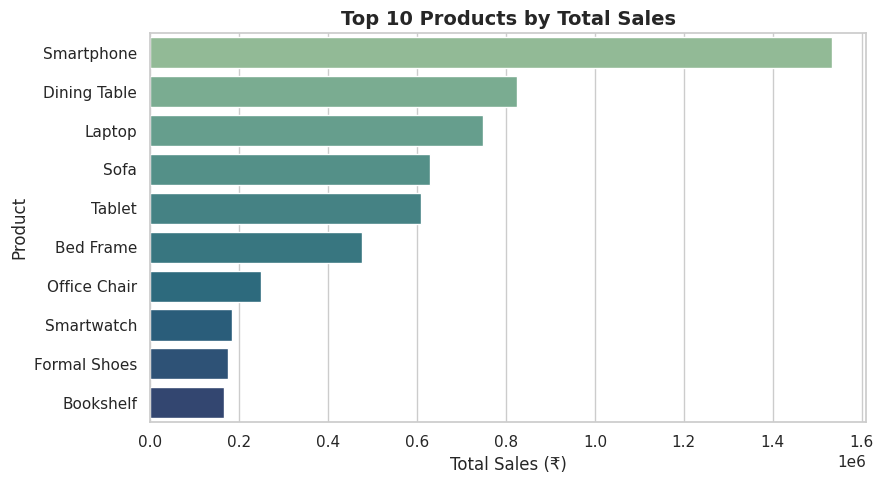

In [38]:
plt.figure(figsize=(9, 5))
sns.barplot(x=top_products.values, y=top_products.index, hue=top_products.index,
            palette="crest", legend=False)
plt.title("Top 10 Products by Total Sales", fontsize=14, fontweight="bold")
plt.xlabel("Total Sales (₹)")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig("../visualizations/top_products.png")
plt.show()


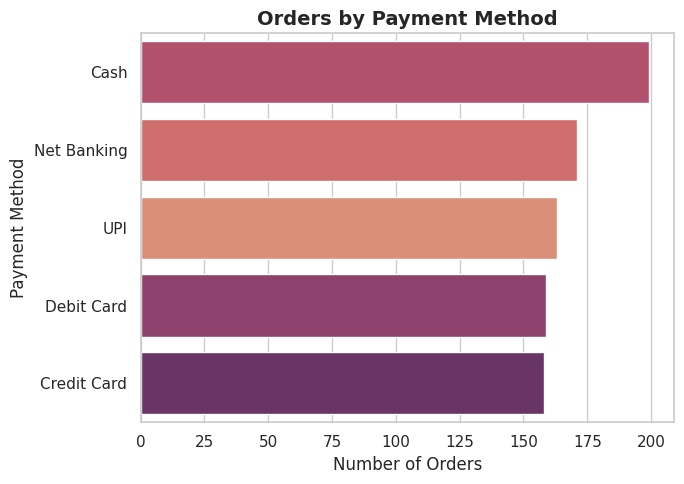

In [39]:
plt.figure(figsize=(7, 5))
sns.countplot(y="Payment_Method", data=df, order=payment_counts.index,
              hue="Payment_Method", palette="flare", legend=False)
plt.title("Orders by Payment Method", fontsize=14, fontweight="bold")
plt.xlabel("Number of Orders")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.savefig("../visualizations/payment_method_counts.png")
plt.show()


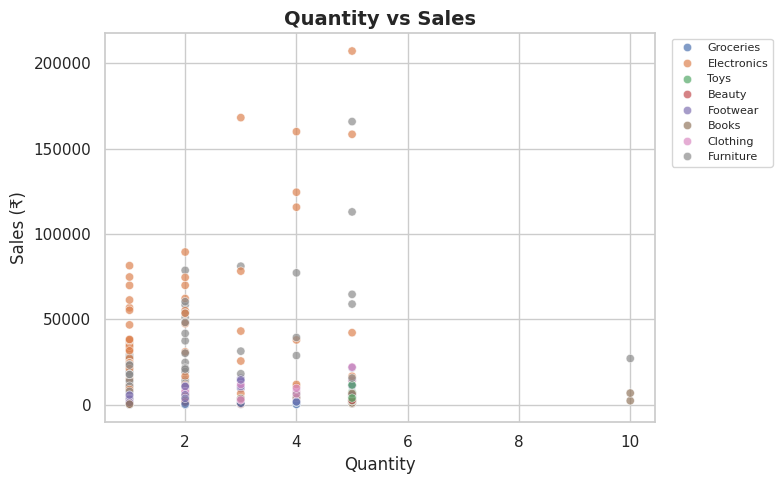

In [40]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="Quantity", y="Sales", data=df, hue="Category", alpha=0.7)
plt.title("Quantity vs Sales", fontsize=14, fontweight="bold")
plt.xlabel("Quantity")
plt.ylabel("Sales (₹)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("../visualizations/quantity_vs_sales.png")
plt.show()


## 15. Key Insights

For each insight: **Observation** (what the numbers show) → **Interpretation**
(what it likely means) → *(Speculation, only where explicitly marked)*.

1. **Electronics and Furniture dominate revenue.**
   *Observation:* Electronics (₹31.8L) and Furniture (₹23.5L) together contribute
   roughly 82% of total sales, while Groceries and Books contribute under 2%
   combined.
   *Interpretation:* Revenue is driven by a small number of high-ticket
   categories, not by transaction volume — Groceries/Books likely have many
   low-value orders that don't move the total much.

2. **Ahmedabad, Delhi, and Pune are the top revenue cities.**
   *Observation:* These three cities lead total sales, though the gap to the
   next tier of cities (Bangalore, Chennai) is modest.
   *Interpretation:* Demand is fairly distributed across metro cities rather
   than concentrated in one location.

3. **Cash is still the most-used payment method**, followed closely by Net
   Banking, UPI, Debit Card, and Credit Card — all five methods are used at
   broadly similar rates (roughly 18-23% of orders each).
   *Interpretation:* No single payment method dominates, suggesting the
   business should keep supporting all these options rather than optimizing
   for just one.

4. **Quantity and Sales are only weakly correlated** (~0.25).
   *Observation:* Buying more units doesn't strongly predict a higher sales
   value.
   *Interpretation:* This makes sense — a single ₹45,000 laptop produces far
   more revenue than 5 units of a ₹200 item, so **unit price**, not quantity,
   is the main driver of order value.

5. **Average customer ratings sit around 2.9-3.1 across most categories**,
   with Furniture/Clothing slightly higher and Footwear slightly lower.
   *Interpretation:* Ratings are fairly uniform across categories — there
   isn't one category with a standout satisfaction problem based on this data.

*(Speculation: if this were real business data, the low Grocery/Books revenue
combined with steady order counts might suggest these are used as "add-on"
categories rather than primary purchase drivers — but this dataset does not
contain basket-level data to confirm that.)*


## 16. Conclusion

Starting from a deliberately messy raw dataset, we:

- Diagnosed missing values, duplicates, inconsistent categories, invalid
  values, mixed data types, and outliers.
- Cleaned the data using column-appropriate strategies rather than one-size-
  fits-all rules (median/mode imputation, per-category outlier handling,
  domain-aware caps).
- Explored the cleaned data to answer concrete business questions.
- Visualized the findings clearly, and translated them into insights that are
  grounded in the actual numbers.

This mirrors the real workflow of a data analyst: **raw data is never ready
to analyze — cleaning it thoughtfully is what makes the rest of the analysis
trustworthy.**
